# Ecobici — Impacto ambiental de la política de redistribución propuesta

En este notebook se analiza el impacto ambiental potencial de implementar una estrategia optimizada de redistribución de bicicletas en la subred de Ecobici conformada por las estaciones de Buenavista y Reforma estudiadas en las etapas anteriores.

A partir de los resultados del modelo estocástico, la optimización de la política del camión y las simulaciones de escenarios, se busca estimar:

- La reducción de rechazos por falta de bicicletas y espacios disponibles.
- El incremento potencial de viajes en bicicleta.
- La posible sustitución de viajes en vehículos particulares.
- La reducción potencial de emisiones de CO₂.
- El impacto ambiental asociado a la redistribución de bicicletas.
- La incertidumbre de las estimaciones bajo diferentes escenarios de demanda.

El objetivo es determinar si la política propuesta, además de mejorar el funcionamiento del sistema, podría generar beneficios ambientales.

Los resultados representan estimaciones basadas en el modelo y no beneficios ambientales observados directamente.

## 1. Obtención y preparación de datos

### 1.1 Configuración del entorno

Se importan las librerías necesarias para el análisis.
Se utilizarán los resultados previamente obtenidos para mantener la consistencia entre el modelo estocástico, la política de redistribución y el análisis ambiental.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

### 1.2 Identificación de los archivos disponibles

Antes de realizar los cálculos ambientales, se identifican los archivos generados en las etapas anteriores del proyecto.

Estos archivos contienen información sobre el comportamiento de las estaciones, las políticas de redistribución y los resultados de las simulaciones.

La finalidad es identificar las fuentes de información necesarias para el análisis ambiental, sin volver a ejecutar los modelos previamente desarrollados.

In [2]:
ruta = Path.cwd()

archivos_csv = list(ruta.rglob("*.csv"))

for archivo in archivos_csv:
    print(archivo.relative_to(ruta))

outputs/tablas/camion_politicas.csv
outputs/tablas/log_limpieza.csv
outputs/tablas/camion_validacion.csv
outputs/tablas/sim_variacion_dias.csv
outputs/tablas/resumen_meses.csv
outputs/tablas/camion_actual_hora.csv
outputs/tablas/escenarios.csv
outputs/tablas/sim_escenarios.csv
outputs/tablas/camion_frontera.csv
outputs/tablas/prob_falla_hora.csv
outputs/tablas/mejor_x0.csv
outputs/tablas/justificacion_mm1n.csv
outputs/tablas/rechazos_x0.csv
outputs/tablas/sim_validacion_kolmogorov.csv
outputs/tablas/sim_validacion_datos.csv
outputs/tablas/control_archivos.csv
outputs/tablas/lotes.csv
outputs/tablas/tasas_modelo.csv
outputs/tablas/validacion_huecos.csv
outputs/tablas/camion_actual.csv
outputs/tablas/descriptivas_estacion_hora.csv
outputs/tablas/camion_propuesta.csv
outputs/tablas/sim_criterios.csv
outputs/tablas/validacion_meses.csv
outputs/tablas/log_limpieza_2026-09.csv


### 1.3 Selección de las fuentes de información

De los archivos disponibles se seleccionan principalmente los siguientes:

| Archivo | Información utilizada |
|---|---|
| camion_politicas.csv | Comparación de rechazos y demanda atendida entre políticas. |
| sim_escenarios.csv | Resultados de las simulaciones bajo diferentes niveles de demanda. |
| camion_actual.csv | Movimientos de bicicletas bajo la política actual. |
| camion_propuesta.csv | Movimientos de bicicletas bajo la política optimizada. |

La información de estos archivos permitirá comparar el funcionamiento actual del sistema con la estrategia propuesta y estimar sus posibles beneficios ambientales.

In [3]:
ruta_tablas = ruta / "outputs" / "tablas"

sim_escenarios = pd.read_csv(ruta_tablas / "sim_escenarios.csv")
camion_actual = pd.read_csv(ruta_tablas / "camion_actual.csv")
camion_propuesta = pd.read_csv(ruta_tablas / "camion_propuesta.csv")
camion_politicas = pd.read_csv(ruta_tablas / "camion_politicas.csv")

### 1.4 Exploración de los resultados previos

Se realiza una revisión de los archivos seleccionados
para identificar las variables que serán utilizadas
en el análisis ambiental.

Las principales variables de interés son:

- Rechazos por falta de bicicletas.
- Rechazos por falta de espacios disponibles (docks).
- Porcentaje de demanda atendida.
- Bicicletas redistribuidas por el camión.
- Resultados bajo diferentes niveles de demanda.

Estas variables permitirán relacionar la mejora operativa
del sistema con sus posibles beneficios ambientales.

In [4]:
print("SIMULACIÓN DE ESCENARIOS")
display(sim_escenarios.head())

print("POLÍTICA ACTUAL")
display(camion_actual.head())

print("POLÍTICA PROPUESTA")
display(camion_propuesta.head())

print("COMPARACIÓN DE POLÍTICAS")
display(camion_politicas.head())

SIMULACIÓN DE ESCENARIOS


,política,escenario,rechazos (media),IC 95 %,rechazos P95,% demanda atendida,bicis movidas
0,sin camión,baja,1056.4,7.6,1257.0,65.2,0.0
1,actual,baja,232.7,5.5,396.0,92.3,998.8
2,propuesta,baja,115.3,2.6,189.0,96.2,964.3
3,propuesta (camión de 40),baja,201.6,4.9,339.0,93.3,876.7
4,sin camión,base,1092.2,7.3,1293.0,64.9,0.0


POLÍTICA ACTUAL


,Unnamed: 0,grupo,saca (día),deja (día),saca (noche),deja (noche)
0,271-272,Buenavista,376.157895,233.000000,45.105263,15.789474
1,273-274,Buenavista,93.368421,40.894737,19.947368,7.684211
2,014,Reforma,93.105263,40.842105,1.368421,0.105263
3,027,Reforma,49.473684,31.526316,1.157895,0.315789
4,018,Reforma,58.789474,31.526316,0.631579,0.000000


POLÍTICA PROPUESTA


,estación,hora,frontera,deja la estación con,bicis que deja (prom.),bicis que saca (prom.),bicis movidas (p95)
0,271-272,7:00,4,72,54.4,0.0,72
1,271-272,8:00,6,72,54.6,0.0,72
2,271-272,8:30,7,72,52.5,0.0,70
3,271-272,9:00,8,65,45.5,0.0,63
4,271-272,9:30,9,57,26.7,0.0,41


COMPARACIÓN DE POLÍTICAS


,política,estación,x0,sin bici,sin dock,rechazos,% demanda atendida,horas vacía,horas llena,bicis dejadas,bicis sacadas
0,sin camión,271-272,74.0,262.44,425.65,688.09,42.40,4.45,5.43,0.00,0.00
1,actual,271-272,74.0,38.94,65.38,104.32,91.27,1.37,1.00,225.67,370.31
2,sin camión,273-274,70.0,66.77,95.64,162.41,60.72,3.88,5.38,0.00,0.00
3,actual,273-274,70.0,29.41,12.51,41.92,89.86,2.24,1.63,38.11,90.41
4,sin camión,014,0.0,32.10,84.29,116.39,76.31,3.05,2.77,0.00,0.00


## 2. Reducción de rechazos

### 2.1 Comparación de rechazos por política

Para determinar la mejora en la disponibilidad del servicio,
se comparan tres estrategias de redistribución:

- Sin camión: el sistema funciona sin redistribución.
- Actual: representa la política actual modelada.
- Propuesta: representa la estrategia optimizada.

Se suman los rechazos esperados de las cinco estaciones,
diferenciando entre los ocasionados por falta de bicicletas
y aquellos ocasionados por falta de espacios disponibles.

Desde una perspectiva ambiental, los rechazos por falta
de bicicletas son especialmente relevantes, ya que
representan oportunidades de viaje que no pudieron
ser atendidas.

In [5]:
resumen_rechazos = camion_politicas.groupby("política")[
    ["sin bici", "sin dock", "rechazos",
     "bicis dejadas", "bicis sacadas"]
].sum()

display(resumen_rechazos.round(2))

,sin bici,sin dock,rechazos,bicis dejadas,bicis sacadas
política,,,,,
actual,106.27,100.53,206.80,356.99,650.89
propuesta,56.31,46.34,102.66,354.46,650.10
sin camión,401.27,687.70,1088.97,0.00,0.00


#### Interpretación de los resultados

La política propuesta reduce los rechazos esperados
de 206.80 a 102.66 por día, lo que representa una
disminución del 50.36%.

Los rechazos por falta de bicicletas disminuyen de
106.27 a 56.31, evitando aproximadamente 49.96 rechazos
diarios de retiro.

Por otro lado, los rechazos por falta de espacios
disponibles disminuyen de 100.53 a 46.34 por día.

Desde una perspectiva ambiental, las 49.96 oportunidades
adicionales de retiro serán utilizadas como punto de
partida para estimar los viajes adicionales en bicicleta.

Sin embargo, no se puede asegurar que todas estas
oportunidades se conviertan en viajes adicionales ni
que sustituyan directamente viajes en automóvil.

### 2.2 Comparación de escenarios de demanda

La demanda de bicicletas puede variar dependiendo
del día, los horarios y las condiciones externas.

Por esta razón, se analiza el comportamiento de la
política propuesta bajo tres escenarios de demanda:
baja, base y alta.

La cantidad de rechazos evitados se calcula mediante:

$$
R_{evitados} = R_{actual} - R_{propuesta}
$$

Mientras que el porcentaje de reducción se obtiene como:

$$
Reducción (\%) =
\frac{R_{actual}-R_{propuesta}}{R_{actual}}
\times 100
$$

El objetivo es determinar si los beneficios de la
estrategia propuesta se mantienen ante diferentes
niveles de demanda.

In [6]:
comparacion_escenarios = sim_escenarios.pivot(
    index="escenario",
    columns="política",
    values="rechazos (media)"
)

comparacion_escenarios["rechazos evitados"] = (
    comparacion_escenarios["actual"] -
    comparacion_escenarios["propuesta"]
)

comparacion_escenarios["reducción (%)"] = (
    comparacion_escenarios["rechazos evitados"] /
    comparacion_escenarios["actual"] * 100
)

display(comparacion_escenarios.round(2))

política,actual,propuesta,propuesta (camión de 40),sin camión,rechazos evitados,reducción (%)
escenario,,,,,,
alta,410.9,187.7,339.0,1286.5,223.2,54.32
baja,232.7,115.3,201.6,1056.4,117.4,50.45
base,270.6,126.4,226.2,1092.2,144.2,53.29


#### Interpretación de los resultados

La política propuesta presenta una reducción superior
al 50% de los rechazos en los tres escenarios analizados.

- Demanda baja: se evitan 117.4 rechazos diarios,
  equivalentes a una reducción del 50.45%.

- Demanda base: se evitan 144.2 rechazos diarios,
  equivalentes a una reducción del 53.29%.

- Demanda alta: se evitan 223.2 rechazos diarios,
  equivalentes a una reducción del 54.32%.

Los resultados muestran que la estrategia propuesta
mantiene sus beneficios incluso cuando aumenta la
demanda del servicio.

El mayor beneficio se presenta en el escenario de
demanda alta, donde se evita una mayor cantidad de
rechazos.

Esto indica que la estrategia podría generar mayores
beneficios operativos durante los días de mayor demanda.

### 2.3 Visualización de la reducción de rechazos

Se construyen dos gráficas comparativas para facilitar
la interpretación de los resultados.

La primera muestra la cantidad de rechazos por falta
de bicicletas y espacios disponibles para cada política.

La segunda compara los rechazos totales de la política
actual y la propuesta bajo los diferentes escenarios
de demanda.

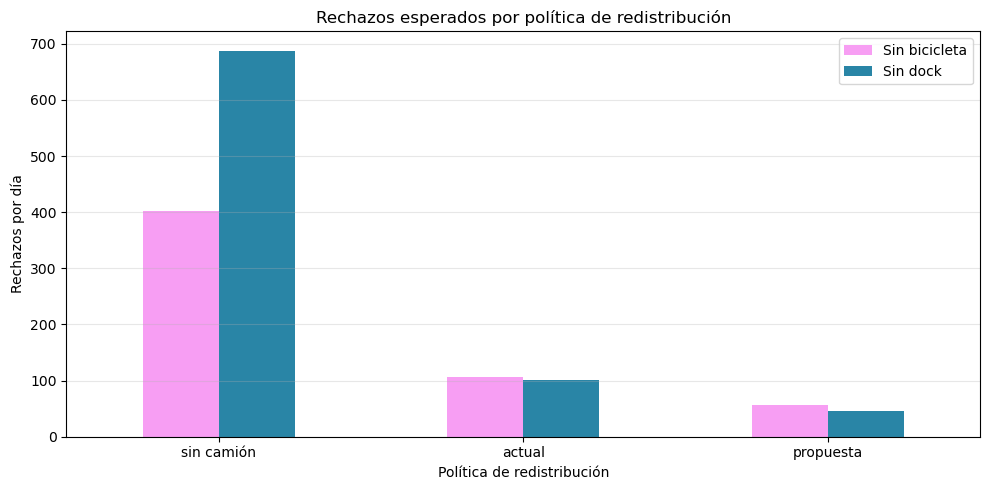

In [12]:
orden_politicas = ["sin camión", "actual", "propuesta"]

resumen_rechazos.loc[orden_politicas, [
    "sin bici", "sin dock"
]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#F79EF3", "#2985a6"],
    rot=0
)

plt.title("Rechazos esperados por política de redistribución")
plt.xlabel("Política de redistribución")
plt.ylabel("Rechazos por día")
plt.legend(["Sin bicicleta", "Sin dock"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

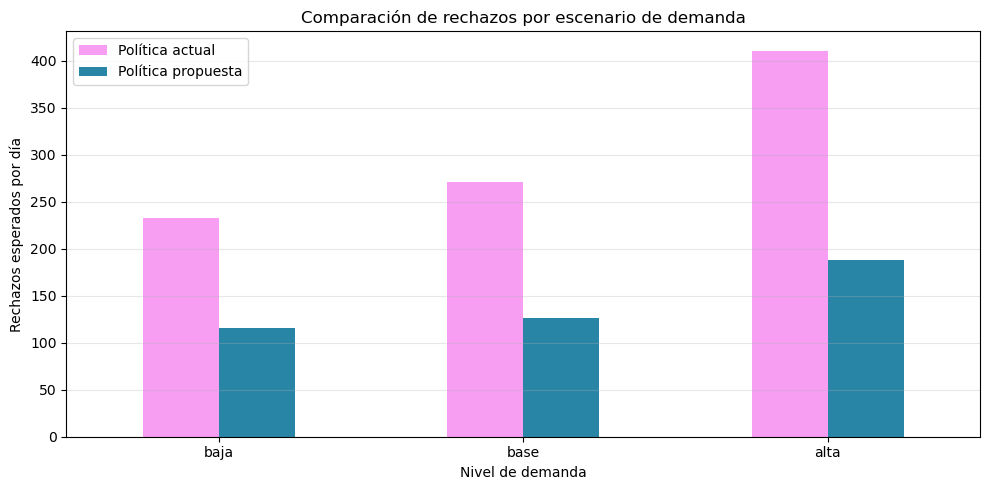

In [ ]:
orden_escenarios = ["baja", "base", "alta"]

comparacion_escenarios.loc[orden_escenarios, [
    "actual", "propuesta"
]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#", "#2985a6"],
    rot=0
)

plt.title("Comparación de rechazos por escenario de demanda")
plt.xlabel("Nivel de demanda")
plt.ylabel("Rechazos esperados por día")
plt.legend(["Política actual", "Política propuesta"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación de las gráficas

En la primera gráfica se observa que, cuando no existe
una estrategia de redistribución, la cantidad de rechazos
por falta de bicicletas y espacios disponibles es
considerablemente mayor.

La política actual permite disminuir estos rechazos;
sin embargo, la política propuesta obtiene mejores
resultados en ambos indicadores.

En la segunda gráfica se observa que la política
propuesta mantiene una menor cantidad de rechazos
en los tres escenarios de demanda.

Además, conforme aumenta la demanda, la diferencia
entre la política actual y la propuesta es mayor.

Estos resultados muestran que la optimización de la
redistribución permite mejorar la disponibilidad del
servicio, generando oportunidades adicionales para
realizar viajes en bicicleta y, potencialmente,
beneficios ambientales.

## 3. Estimación de viajes adicionales

### 3.1 Estimación de oportunidades adicionales de viaje

Para estimar el impacto ambiental de la política
propuesta, primero se calcula la cantidad de
oportunidades adicionales de viaje que se generan
al mejorar la disponibilidad de bicicletas.

En este análisis únicamente se consideran los
rechazos por falta de bicicletas, debido a que
los rechazos por falta de espacios disponibles
corresponden a usuarios que buscan finalizar un viaje.

La cantidad de oportunidades adicionales se
calcula mediante:

$$
V_{potenciales} = R_{actual}^{bici} - R_{propuesta}^{bici}
$$

Donde:

- $V_{potenciales}$: oportunidades adicionales de viaje.
- $R_{actual}^{bici}$: rechazos por falta de bicicletas
  bajo la política actual.
- $R_{propuesta}^{bici}$: rechazos por falta de bicicletas
  bajo la política propuesta.

Este resultado representa una estimación del potencial
de viajes adicionales y no una cantidad garantizada
de viajes realizados.

In [13]:
rechazos_bici_actual = resumen_rechazos.loc[
    "actual", "sin bici"
]

rechazos_bici_propuesta = resumen_rechazos.loc[
    "propuesta", "sin bici"
]

viajes_potenciales = (
    rechazos_bici_actual - rechazos_bici_propuesta
)

reduccion_rechazos_bici = (
    viajes_potenciales / rechazos_bici_actual * 100
)

resumen_viajes = pd.DataFrame({
    "Indicador": [
        "Rechazos sin bicicleta - actual",
        "Rechazos sin bicicleta - propuesta",
        "Oportunidades adicionales por día",
        "Reducción de rechazos (%)"
    ],
    "Resultado": [
        rechazos_bici_actual,
        rechazos_bici_propuesta,
        viajes_potenciales,
        reduccion_rechazos_bici
    ]
})

display(resumen_viajes.round(2))

,Indicador,Resultado
0,Rechazos sin bicicleta - actual,106.27
1,Rechazos sin bicicleta - propuesta,56.31
2,Oportunidades adicionales por día,49.96
3,Reducción de rechazos (%),47.01


#### Interpretación de los resultados

La política propuesta permite reducir los rechazos
por falta de bicicletas de 106.27 a 56.31 por día,
lo que representa una disminución del 47.01%.

Esta reducción genera aproximadamente 49.96
oportunidades adicionales de viaje por día en
la subred analizada.

Este resultado será utilizado como punto de partida
para estimar el impacto ambiental de la estrategia
de redistribución propuesta.

Es importante mencionar que no todas las oportunidades
adicionales necesariamente se convierten en viajes
efectivos ni sustituyen viajes en automóvil.

### 3.2 Conversión a viajes efectivos

No todas las oportunidades adicionales de viaje
necesariamente se convierten en viajes efectivos.

Debido a que no se cuenta con información sobre
el comportamiento individual de los usuarios,
se realiza un análisis de sensibilidad considerando
tres escenarios hipotéticos de conversión:

- Conservador: 25%.
- Intermedio: 50%.
- Optimista: 75%.

La cantidad estimada de viajes adicionales efectivos
se calcula mediante:

$$
V_{efectivos} = V_{potenciales} \times p_c
$$

Donde:

- $V_{efectivos}$: viajes adicionales efectivos estimados.
- $V_{potenciales}$: oportunidades adicionales de viaje.
- $p_c$: proporción de oportunidades que se convierten
  en viajes efectivos.

Los porcentajes utilizados corresponden a supuestos
del análisis de sensibilidad y no a probabilidades
estimadas a partir de datos históricos.

In [14]:
escenarios_conversion = pd.DataFrame({
    "Escenario": [
        "Conservador",
        "Intermedio",
        "Optimista"
    ],
    "Tasa de conversión": [
        0.25,
        0.50,
        0.75
    ]
})

escenarios_conversion["Viajes potenciales por día"] = (
    viajes_potenciales
)

escenarios_conversion["Viajes efectivos por día"] = (
    viajes_potenciales *
    escenarios_conversion["Tasa de conversión"]
)

escenarios_conversion["Conversión (%)"] = (
    escenarios_conversion["Tasa de conversión"] * 100
)

display(escenarios_conversion[[
    "Escenario",
    "Viajes potenciales por día",
    "Conversión (%)",
    "Viajes efectivos por día"
]].round(2))

,Escenario,Viajes potenciales por día,Conversión (%),Viajes efectivos por día
0,Conservador,49.96,25.0,12.49
1,Intermedio,49.96,50.0,24.98
2,Optimista,49.96,75.0,37.47


#### Interpretación de los resultados

Los resultados muestran que la política propuesta
podría generar entre 12.49 y 37.47 viajes adicionales
por día bajo los escenarios de conversión considerados.

En el escenario intermedio se estima que el 50%
de las oportunidades adicionales se convierte en
viajes efectivos, obteniendo un total de 24.98
viajes adicionales por día.

La diferencia entre los escenarios permite observar
la sensibilidad de los resultados ante cambios
en el comportamiento de los usuarios.

Estas estimaciones serán utilizadas para analizar
la posible sustitución de viajes en automóvil y
su impacto sobre las emisiones de CO₂.

### 3.3 Sustitución de viajes en vehículos motorizados particulares

Para estimar los beneficios ambientales de la política
propuesta, se analiza qué proporción de los viajes
adicionales en bicicleta podría sustituir viajes
realizados en vehículos motorizados particulares.

Se utiliza como referencia la Encuesta de Percepción
ECOBICI 2023, realizada por la Secretaría de Movilidad
de la Ciudad de México.

En la pregunta 13, ubicada en la página 17, se pregunta
a los usuarios qué medio de transporte utilizarían
si no tuvieran la opción de realizar su trayecto
en ECOBICI.

Los porcentajes seleccionados para el análisis son:

- Automóvil particular como conductor: 8.25%.
- Motocicleta: 1.48%.

Por lo tanto, la tasa conjunta de sustitución es:

$$
p_s = 0.0825 + 0.0148 = 0.0973
$$

Esto representa una tasa de sustitución de vehículos
motorizados particulares del 9.73%.

#### Justificación de los medios de transporte seleccionados

Se consideran únicamente los automóviles particulares
y las motocicletas, debido a que sustituir estos viajes
por desplazamientos en bicicleta podría evitar
directamente la circulación de un vehículo.

No se incluyen los taxis ni los servicios de transporte
por aplicación, como Uber, DiDi y Cabify, debido a que
estos vehículos pueden continuar circulando en busca
de otros pasajeros, incluso cuando un usuario decide
utilizar ECOBICI.

Tampoco se considera el transporte público, ya que
estos servicios generalmente mantienen sus recorridos
independientemente de la decisión individual de
un usuario.

Esto no significa que la sustitución de estos medios
de transporte no genere beneficios ambientales, sino
que no se cuenta con información suficiente para
cuantificarlos de manera confiable.

Por esta razón, se adopta un enfoque conservador
para evitar sobreestimar los beneficios ambientales.

#### Diferenciación por tipo de vehículo

Aunque los automóviles y las motocicletas se incluyen
dentro de una misma categoría de vehículos motorizados
particulares, sus emisiones se calcularán de manera
diferenciada.

Esto se debe a que presentan distintos niveles de
consumo de combustible y emisiones por kilómetro.

La cantidad de viajes sustituidos se calcula mediante:

$$
V_{auto} = V_{efectivos} \times 0.0825
$$

$$
V_{moto} = V_{efectivos} \times 0.0148
$$

$$
V_{total} = V_{auto} + V_{moto}
$$

Posteriormente, se utilizarán factores de emisión
específicos para cada tipo de vehículo, permitiendo
obtener una estimación conjunta que considere sus
diferencias ambientales.

Los porcentajes utilizados provienen de una encuesta
oficial y se emplean como parámetros de referencia,
ya que no representan mediciones específicas de los
usuarios de las estaciones analizadas.

**Fuente:** Secretaría de Movilidad de la Ciudad de
México. Encuesta de Percepción ECOBICI 2023, página 17.

[Consultar encuesta oficial](https://ecobici.cdmx.gob.mx/wp-content/uploads/2024/10/Encuesta-ECOBICI-2023.pdf)

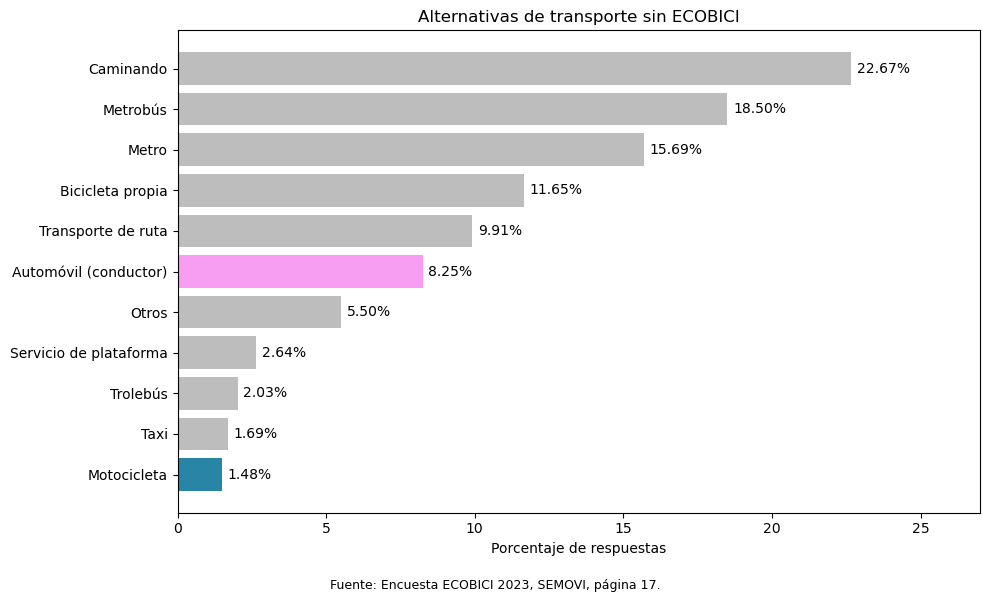

In [16]:
encuesta_movilidad = pd.DataFrame({
    "Medio de transporte": [
        "Caminando",
        "Metrobús",
        "Metro",
        "Bicicleta propia",
        "Transporte de ruta",
        "Automóvil (conductor)",
        "Otros",
        "Servicio de plataforma",
        "Trolebús",
        "Taxi",
        "Motocicleta"
    ],
    "Porcentaje": [
        22.67, 18.50, 15.69, 11.65,
        9.91, 8.25, 5.50, 2.64,
        2.03, 1.69, 1.48
    ]
})

colores = [
    "#F79EF3" if medio == "Automóvil (conductor)"
    else "#2985a6" if medio == "Motocicleta"
    else "#bdbdbd"
    for medio in encuesta_movilidad["Medio de transporte"]
]

plt.figure(figsize=(10, 6))

barras = plt.barh(
    encuesta_movilidad["Medio de transporte"],
    encuesta_movilidad["Porcentaje"],
    color=colores
)

plt.gca().invert_yaxis()
plt.bar_label(barras, fmt="%.2f%%", padding=4)

plt.title("Alternativas de transporte sin ECOBICI")
plt.xlabel("Porcentaje de respuestas")
plt.xlim(0, 27)

plt.figtext(
    0.5, 0.01,
    "Fuente: Encuesta ECOBICI 2023, SEMOVI, página 17.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

In [17]:
tasa_sustitucion_auto = 0.0825
tasa_sustitucion_moto = 0.0148

tasa_sustitucion_total = (
    tasa_sustitucion_auto +
    tasa_sustitucion_moto
)

escenarios_movilidad = escenarios_conversion.copy()

escenarios_movilidad["Viajes en automóvil evitados por día"] = (
    escenarios_movilidad["Viajes efectivos por día"] *
    tasa_sustitucion_auto
)

escenarios_movilidad["Viajes en motocicleta evitados por día"] = (
    escenarios_movilidad["Viajes efectivos por día"] *
    tasa_sustitucion_moto
)

escenarios_movilidad["Total de viajes motorizados evitados"] = (
    escenarios_movilidad["Viajes en automóvil evitados por día"] +
    escenarios_movilidad["Viajes en motocicleta evitados por día"]
)

display(escenarios_movilidad[[
    "Escenario",
    "Viajes efectivos por día",
    "Viajes en automóvil evitados por día",
    "Viajes en motocicleta evitados por día",
    "Total de viajes motorizados evitados"
]].round(2))

,Escenario,Viajes efectivos por día,Viajes en automóvil evitados por día,Viajes en motocicleta evitados por día,Total de viajes motorizados evitados
0,Conservador,12.49,1.03,0.18,1.22
1,Intermedio,24.98,2.06,0.37,2.43
2,Optimista,37.47,3.09,0.55,3.65


In [18]:
peso_auto = (
    tasa_sustitucion_auto /
    tasa_sustitucion_total
)

peso_moto = (
    tasa_sustitucion_moto /
    tasa_sustitucion_total
)

ponderaciones_vehiculos = pd.DataFrame({
    "Tipo de vehículo": [
        "Automóvil particular",
        "Motocicleta"
    ],
    "Tasa de sustitución (%)": [
        tasa_sustitucion_auto * 100,
        tasa_sustitucion_moto * 100
    ],
    "Ponderación (%)": [
        peso_auto * 100,
        peso_moto * 100
    ]
})

display(ponderaciones_vehiculos.round(2))

,Tipo de vehículo,Tasa de sustitución (%),Ponderación (%)
0,Automóvil particular,8.25,84.79
1,Motocicleta,1.48,15.21


#### Interpretación de los resultados

Considerando los porcentajes obtenidos de la Encuesta
de Percepción ECOBICI 2023, se estima que el 9.73%
de los viajes adicionales efectivos podría sustituir
viajes en automóviles particulares y motocicletas.

En el escenario intermedio se estima una sustitución
de 2.06 viajes en automóvil y 0.37 viajes en
motocicleta por día, obteniendo un total de
aproximadamente 2.43 viajes motorizados evitados.

Dentro de los viajes motorizados sustituidos, el
84.79% corresponde a automóviles particulares y
el 15.21% a motocicletas.

Esta distribución permitirá diferenciar las emisiones
evitadas de acuerdo con las características de cada
tipo de vehículo.

Los resultados representan valores esperados y no
cantidades exactas de viajes realizados diariamente.